# Importações

In [46]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from dotenv import load_dotenv

from sqlalchemy.engine import URL
from sqlalchemy import create_engine

load_dotenv()

SEED = 42

In [ ]:
url = URL.create(
    drivername="postgresql+psycopg2",
    username=os.getenv("DB_USER"),
    password=os.getenv("DB_PASS"),
    host=os.getenv("DB_HOST"),
    port=int(os.getenv("DB_PORT")),
    database=os.getenv("DB_NAME"),
)

engine = create_engine(url)

# Carregando o Dataset

In [ ]:
query = "SELECT * FROM gold.delivery_delay;"

In [48]:
df = pd.read_sql(query, engine)
df.head(5)

,order_id,is_delayed,purchase_month,purchase_day_of_week,purchase_hour,approval_time_hours,estimated_delivery_days,item_count,unique_product_count,seller_count,...,total_freight,total_weight_g,total_volume_cm3,distance_km,shipping_state_type,payment_count,payment_type_count,max_installments,category_count,main_product_category
0,467e12527db98ba8ff31b60f0a2cddfd,0,8,5,5,0.205278,24.770764,1,1,1,...,17.60,900.0,4256.0,445.274373,1,1.0,1.0,2.0,1,housewares
1,7c3fe5194219d774a7d238f80d4c9919,0,4,2,11,0.321667,15.520787,2,1,1,...,16.60,900.0,36000.0,127.722200,1,1.0,1.0,1.0,1,pet_shop
2,5c6e2b3612d27ef59e6a4a062b8d6cda,0,4,6,12,79.275833,22.191748,2,1,1,...,35.94,1900.0,28000.0,377.788242,0,1.0,1.0,10.0,1,furniture_decor
3,000c3e6612759851cc3cbb4b83257986,0,8,6,10,65.443056,16.850324,1,1,1,...,13.71,1800.0,4096.0,249.151879,1,1.0,1.0,1.0,1,sports_leisure
4,0572c996d9b4a7645bb071a158a64bbb,0,11,1,21,0.235278,20.078160,2,1,1,...,33.40,2100.0,23232.0,339.530768,0,2.0,2.0,1.0,1,furniture_decor


In [49]:
df.shape
# 21 features

(96456, 21)

In [50]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96456 entries, 0 to 96455
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   order_id                 96456 non-null  object 
 1   is_delayed               96456 non-null  int64  
 2   purchase_month           96456 non-null  int64  
 3   purchase_day_of_week     96456 non-null  int64  
 4   purchase_hour            96456 non-null  int64  
 5   approval_time_hours      96456 non-null  float64
 6   estimated_delivery_days  96450 non-null  float64
 7   item_count               96456 non-null  int64  
 8   unique_product_count     96456 non-null  int64  
 9   seller_count             96456 non-null  int64  
 10  total_price              96456 non-null  float64
 11  total_freight            96456 non-null  float64
 12  total_weight_g           96434 non-null  float64
 13  total_volume_cm3         96440 non-null  float64
 14  distance_km           

In [51]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
is_delayed,96456.0,0.081135,0.273044,0.000000,0.000000,0.000000,0.000000,1.000000e+00
purchase_month,96456.0,6.031652,3.228319,1.000000,3.000000,6.000000,8.000000,1.200000e+01
purchase_day_of_week,96456.0,2.912146,1.894549,0.000000,1.000000,3.000000,5.000000,6.000000e+00
purchase_hour,96456.0,14.773099,5.328400,0.000000,11.000000,15.000000,19.000000,2.300000e+01
approval_time_hours,96456.0,10.277598,20.536068,0.000000,0.215278,0.343333,14.517014,7.414436e+02
estimated_delivery_days,96450.0,23.308144,8.762822,0.020498,17.906195,22.669959,28.067595,1.535760e+02
item_count,96456.0,1.142220,0.538854,1.000000,1.000000,1.000000,1.000000,2.100000e+01
unique_product_count,96456.0,1.038546,0.227967,1.000000,1.000000,1.000000,1.000000,8.000000e+00
seller_count,96456.0,1.013903,0.123550,1.000000,1.000000,1.000000,1.000000,5.000000e+00
total_price,96456.0,137.042574,209.064238,0.850000,45.900000,86.500000,149.900000,1.344000e+04


In [ ]:
df.isnull().sum()
# total_weight_g              22
# total_volume_cm3            16
# distance_km                480

order_id                     0
is_delayed                   0
purchase_month               0
purchase_day_of_week         0
purchase_hour                0
approval_time_hours          0
estimated_delivery_days      6
item_count                   0
unique_product_count         0
seller_count                 0
total_price                  0
total_freight                0
total_weight_g              22
total_volume_cm3            16
distance_km                480
shipping_state_type          0
payment_count                1
payment_type_count           1
max_installments             1
category_count               0
main_product_category        0
dtype: int64

In [53]:
print("Linhas duplicadas:", df.duplicated().sum())
print("Order IDs duplicados:", df["order_id"].duplicated().sum())

Linhas duplicadas: 0
Order IDs duplicados: 0


In [ ]:
target_counts = (df["is_delayed"].value_counts().sort_index())

target_pct = (df["is_delayed"].value_counts(normalize=True).sort_index().mul(100))

target_summary = pd.DataFrame({
    "quantidade": target_counts,
    "percentual": target_pct})

target_summary
# 8% dos pedidos foram atrasados

,quantidade,percentual
is_delayed,,
0,88630,91.886456
1,7826,8.113544


### Correlação entre as features

Foi utilizada a correlação de Spearman devido à presença de variáveis
com distribuições assimétricas e valores extremos.

A maior correlação observada ocorreu entre `payment_count` e
`payment_type_count` (0,87), seguida por `total_weight_g` e
`total_volume_cm3` (0,78).

Também foram observadas relações relevantes entre variáveis logísticas,
como distância, prazo estimado e valor do frete.

Apesar dessas associações, nenhuma feature foi removida nesta etapa.
As variáveis correlacionadas representam aspectos distintos dos pedidos.

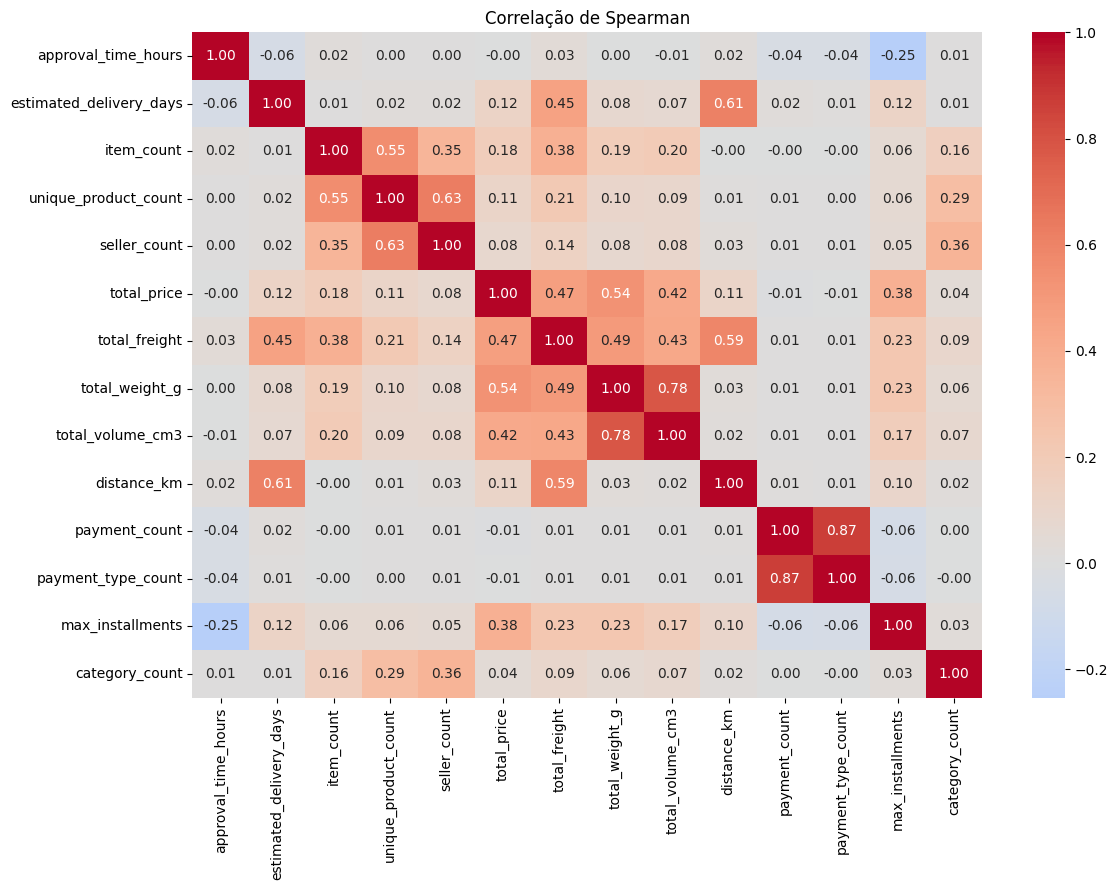

In [61]:
corr_features = ["approval_time_hours","estimated_delivery_days","item_count","unique_product_count","seller_count","total_price","total_freight","total_weight_g","total_volume_cm3","distance_km","payment_count","payment_type_count","max_installments","category_count",]

corr = df[corr_features].corr(method="spearman")

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlação de Spearman")
plt.tight_layout()
plt.show()

### Perfil dos pedidos atrasados

A comparação entre pedidos atrasados e não atrasados revelou diferenças
principalmente nas características logísticas.

Pedidos atrasados apresentaram maior distância entre vendedor e cliente,
maiores valores de frete, peso e preço, além de um prazo estimado de
entrega ligeiramente menor.

A distância apresentou uma das diferenças mais expressivas: a distância
mediana passou de aproximadamente 428 km nos pedidos não atrasados para
512 km nos pedidos atrasados.

Por outro lado, características relacionadas à quantidade de itens,
produtos, vendedores e pagamentos apresentaram diferenças relativamente
pequenas entre as classes.

In [62]:
continuous_features = [
    "approval_time_hours",
    "estimated_delivery_days",
    "total_price",
    "total_freight",
    "total_weight_g",
    "total_volume_cm3",
    "distance_km",
]

df.groupby("is_delayed")[continuous_features].median().T

is_delayed,0,1
approval_time_hours,0.338889,0.413472
estimated_delivery_days,22.856308,21.561377
total_price,85.500000,89.900000
total_freight,17.070000,18.055000
total_weight_g,750.000000,800.000000
total_volume_cm3,7250.000000,7296.000000
distance_km,428.344544,512.260143


In [63]:
df.groupby("is_delayed")[continuous_features].mean().T

is_delayed,0,1
approval_time_hours,10.097781,12.314041
estimated_delivery_days,23.470917,21.464078
total_price,136.067449,148.085933
total_freight,22.623912,24.623620
total_weight_g,2363.547874,2651.832098
total_volume_cm3,17229.489020,18488.372860
distance_km,589.815794,738.874700


In [64]:
discrete_features = [
    "item_count",
    "unique_product_count",
    "seller_count",
    "payment_count",
    "payment_type_count",
    "max_installments",
    "category_count",
]

df.groupby("is_delayed")[discrete_features].mean().T

is_delayed,0,1
item_count,1.144759,1.113468
unique_product_count,1.040043,1.021595
seller_count,1.014927,1.002300
payment_count,1.044895,1.038339
payment_type_count,1.022882,1.019681
max_installments,2.921076,3.010351
category_count,0.994471,0.986839


### Desbalanceamento da variável alvo

A variável alvo apresenta forte desbalanceamento: aproximadamente 91,9%
dos pedidos foram entregues dentro do prazo, enquanto 8,1% apresentaram
atraso.

Consequentemente, accuracy isoladamente não será uma métrica adequada para
avaliar os modelos. A etapa de modelagem irá considerar métricas como
precision, recall, F1-score, PR-AUC e ROC-AUC.

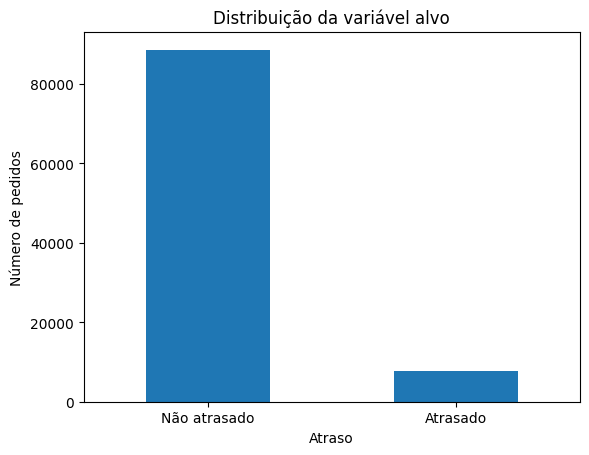

In [65]:
target_dist = df["is_delayed"].value_counts().sort_index()

ax = target_dist.plot(kind="bar")

ax.set_title("Distribuição da variável alvo")
ax.set_xlabel("Atraso")
ax.set_ylabel("Número de pedidos")
ax.set_xticklabels(["Não atrasado", "Atrasado"], rotation=0)

plt.show()

## Conclusões

- A variável alvo é desbalanceada, com aproximadamente 8,1% dos pedidos
  classificados como atrasados.
- Foram encontrados poucos valores ausentes em peso, volume, distância
  e informações de pagamento.
- Algumas variáveis apresentam distribuições fortemente assimétricas e
  valores extremos, porém esses registros não foram removidos
  por poderem representar pedidos legítimos.
- A análise de correlação revelou associações relevantes entre algumas
  features, mas não justificou remoção de variáveis nesta etapa.